In [1]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.transforms as mtransforms

from plot_style import C, apply

FIG = Path("figs")
DATA_PATH = FIG / "data" / "pseudo_arclength_data.npz"
OUTPUT = FIG / "Fig11.pdf"

apply()

with np.load(DATA_PATH) as data:
    branch_ratio = data["branch_r"]
    leading_real_eigenvalue = data["leading_real_eigenvalue"]
    stable_mask = data["stable_mask"].astype(bool)
    wrap_norm = data["wrap_norm"]
    fold_ratio = float(data["fold_r"])
    R_ONSET_INTERVAL = data["r_onset_ci"]

In [2]:
def panel_label(ax, label, dx_pt=-12.0, dy_pt=4.0, fontsize=8.6):
    transform = ax.transAxes + mtransforms.ScaledTranslation(
        dx_pt / 72.0, dy_pt / 72.0, ax.figure.dpi_scale_trans
    )
    ax.text(
        0.0, 1.0, label, transform=transform, ha="left", va="bottom",
        fontsize=fontsize, fontweight="bold", color="#222222",
        clip_on=False, zorder=30,
    )

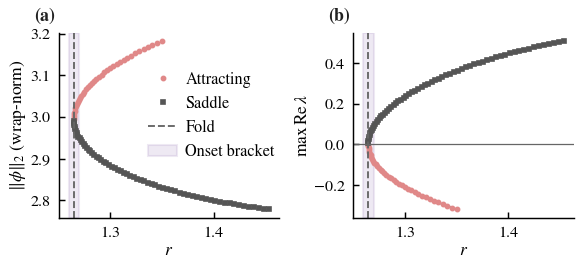

In [3]:
FIGSIZE = (3.8, 1.7)
TICK_FONT_SIZE = 6.4 * 1.2
LABEL_FONT_SIZE = 7.0 * 1.2
LEGEND_FONT_SIZE = 6.0 * 1.3
PANEL_FONT_SIZE = 7.2 * 1.2
MARKER_SIZE = 2
BRANCH_LINE_WIDTH = 1.0
REFERENCE_LINE_WIDTH = 0.9
ZERO_LINE_WIDTH = 0.6

SINK_COLOR = C["red"]
SADDLE_COLOR = "#555555"

fig, axes = plt.subplots(1, 2, figsize=FIGSIZE, constrained_layout=False)
for axis in axes:
    axis.tick_params(axis="both", direction="in", labelsize=TICK_FONT_SIZE, pad=4.0)
    axis.xaxis.labelpad = 1.4
    axis.yaxis.labelpad = 1.4

axes[0].plot(
    branch_ratio[stable_mask], wrap_norm[stable_mask], "o",
    color=SINK_COLOR, markersize=MARKER_SIZE, label="Attracting",
)
axes[0].plot(
    branch_ratio[~stable_mask], wrap_norm[~stable_mask], "s",
    color=SADDLE_COLOR, markersize=MARKER_SIZE, label="Saddle",
)
axes[0].axvline(
    fold_ratio, color="0.4", linestyle="--", linewidth=REFERENCE_LINE_WIDTH,
    label="Fold",
)
axes[0].axvspan(
    R_ONSET_INTERVAL[0], R_ONSET_INTERVAL[1],
    color=C["purple"], alpha=0.18, label="Onset bracket",
)
axes[0].set_xlabel(r"$r$", fontsize=LABEL_FONT_SIZE)
axes[0].set_ylabel(r"$\|\phi\|_{2}$ (wrap-norm)", fontsize=LABEL_FONT_SIZE)
axes[0].legend(
    loc="best", fontsize=LEGEND_FONT_SIZE, bbox_to_anchor=(0.35, 0.55),
    framealpha=0.0, facecolor="none", edgecolor="none",
)

axes[1].plot(
    branch_ratio, leading_real_eigenvalue, "-",
    color="0.6", linewidth=BRANCH_LINE_WIDTH,
)
axes[1].plot(
    branch_ratio[stable_mask], leading_real_eigenvalue[stable_mask], "o",
    color=SINK_COLOR, markersize=MARKER_SIZE,
)
axes[1].plot(
    branch_ratio[~stable_mask], leading_real_eigenvalue[~stable_mask], "s",
    color=SADDLE_COLOR, markersize=MARKER_SIZE,
)
axes[1].axhline(0.0, color="0.4", linewidth=ZERO_LINE_WIDTH)
axes[1].axvline(
    fold_ratio, color="0.4", linestyle="--", linewidth=REFERENCE_LINE_WIDTH,
)
axes[1].axvspan(
    R_ONSET_INTERVAL[0], R_ONSET_INTERVAL[1],
    color=C["purple"], alpha=0.18,
)
axes[1].set_xlabel(r"$r$", fontsize=LABEL_FONT_SIZE)
axes[1].set_ylabel(r"$\max\,\mathrm{Re}\,\lambda$", fontsize=LABEL_FONT_SIZE)

for panel, axis in enumerate(axes):
    panel_label(axis, f"({chr(97 + panel)})", fontsize=PANEL_FONT_SIZE)

fig.tight_layout(pad=0.10, h_pad=0.45)
fig.savefig(OUTPUT)
plt.show()